# 04 - Final test evaluation

The one and only time the test seasons (2025-26) are used. It refits **exactly** the configuration chosen in notebook 03 on train + validation, scores it on the test seasons, and analyses where it fails.

Rules
1. **Nothing is chosen here.** The model, features and hyperparameters come from `model_selection.json`. If the test result is disappointing, you report it - you do not go back and change the model and re-run (that would turn the test set into a second validation set).
2. A **lock file** (`test_results.json`) is written after the run. The notebook refuses to run again unless you set `ALLOW_RERUN = True`, so a second look is a deliberate, visible decision.
3. Baselines are refitted on train + validation too, so the comparison is fair.
4. Confidence intervals resample **whole matches**.

## 1. Settings (edit the paths)

In [1]:
TRAIN_PATH     = r"../data/split/train.csv"
VAL_PATH       = r"../data/split/validation.csv"
TEST_PATH      = r"../data/split/test.csv"           # first opened here
SELECTION_PATH = r"../results/model_selection.json"  # written by notebook 03
OUT_DIR        = r"../results/final"

TEST_START_SEASON = 2025
N_BOOT = 2000
RANDOM_STATE = 0
ALLOW_RERUN = False        # set True only if you deliberately want to repeat the test evaluation

## 2. Load, guards and the lock

In [2]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore", category=ConvergenceWarning)

out = Path(OUT_DIR); out.mkdir(parents=True, exist_ok=True)
LOCK = out / "test_results.json"
if LOCK.exists() and not ALLOW_RERUN:
    raise SystemExit(f"{LOCK} already exists: the test set has been evaluated. Set ALLOW_RERUN = True only if you "
                     "really intend to repeat it (and be honest in the report about how many times you looked).")

sel = json.loads(Path(SELECTION_PATH).read_text())
FEATURES, MODEL, PARAMS = sel["features"], sel["model"], sel["params"]
LABEL = "chasing_team_won"
print(f"Selected in notebook 03: {MODEL} on '{sel['feature_set']}' ({len(FEATURES)} features), params {PARAMS}")
print(f"Rule: {sel['selection_rule']}; validation log loss then: {sel['validation_log_loss']:.4f}")

def load(path, name):
    df = pd.read_csv(path, dtype={"match_id": str})
    miss = [c for c in ["match_id", "season", "over", LABEL] + FEATURES if c not in df.columns]
    assert not miss, f"{name} is missing columns: {miss}"
    return df

train, val, test = load(TRAIN_PATH, "train"), load(VAL_PATH, "val"), load(TEST_PATH, "test")
assert train.season.max() < TEST_START_SEASON and val.season.max() < TEST_START_SEASON, "train/val contain test seasons"
assert test.season.min() >= TEST_START_SEASON, f"test file contains season {test.season.min()} < {TEST_START_SEASON}"
assert not (set(test.match_id) & (set(train.match_id) | set(val.match_id))), "a test match also appears in train/val"
assert train.season.max() < val.season.min() <= val.season.max() < test.season.min(), "seasons are not in time order"
full = pd.concat([train, val], ignore_index=True)
y_full, y_te = full[LABEL].to_numpy(), test[LABEL].to_numpy()
print(f"train+val: {full.match_id.nunique()} matches, {len(full)} rows | test: {test.match_id.nunique()} matches, {len(test)} rows, seasons {sorted(test.season.unique())}")

Selected in notebook 03: logreg on 'D +batters+impact' (20 features), params {'C': 0.1}
Rule: simplest candidate within 0.003 of the best validation log loss; validation log loss then: 0.3675
train+val: 1047 matches, 18817 rows | test: 138 matches, 2434 rows, seasons [np.int64(2025), np.int64(2026)]


## 3. Metrics (same definitions as notebook 03)

In [3]:
EPS = 1e-6
clip = lambda p: np.clip(np.asarray(p, dtype=float), EPS, 1 - EPS)
def row_loss(y, p):
    p = clip(p); return -(y * np.log(p) + (1 - y) * np.log(1 - p))
def summarize(y, p):
    p = clip(p)
    return {"log_loss": row_loss(y, p).mean(), "brier": np.mean((p - y) ** 2), "accuracy": np.mean((p >= 0.5) == y)}
def report(preds, y):
    return pd.DataFrame({k: summarize(y, p) for k, p in preds.items()}).T.round(4)
def per_match(loss, ids):
    g = pd.DataFrame({"m": ids, "l": loss}).groupby("m").l.agg(["sum", "count"])
    return g["sum"].to_numpy(), g["count"].to_numpy()
def bootstrap(preds, y, ids, reference, B=N_BOOT, seed=0):
    rng = np.random.default_rng(seed)
    arrs = {k: per_match(row_loss(y, p), ids) for k, p in preds.items()}
    M = len(arrs[reference][0]); idx = rng.integers(0, M, size=(B, M))
    ref = arrs[reference][0][idx].sum(1) / arrs[reference][1][idx].sum(1)
    rows = {}
    for k, (s, n) in arrs.items():
        ll = s[idx].sum(1) / n[idx].sum(1); diff = ll - ref; isref = k == reference
        rows[k] = {"95% CI": f"[{np.percentile(ll, 2.5):.4f}, {np.percentile(ll, 97.5):.4f}]",
                   "diff vs B": np.nan if isref else diff.mean(),
                   "diff 95% CI": "" if isref else f"[{np.percentile(diff, 2.5):.4f}, {np.percentile(diff, 97.5):.4f}]",
                   "P(better than B)": np.nan if isref else (diff < 0).mean()}
    return pd.DataFrame(rows).T

## 4. Refit on train + validation and predict the test seasons

The final model sees 2017-2024 (everything that was available before the test period). Hyperparameters are the ones tuned in notebook 03. For reference, the same model fitted on **train only** is shown too, to see how much the extra season matters.

In [4]:
def make_model(cols):
    if MODEL == "logreg":
        pre = ColumnTransformer([("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                                                   ("scale", StandardScaler())]), cols)])
        return Pipeline([("pre", pre), ("clf", LogisticRegression(C=PARAMS["C"], max_iter=5000))])
    if MODEL == "hgb":
        return HistGradientBoostingClassifier(early_stopping=False, random_state=RANDOM_STATE, **PARAMS)
    raise ValueError(f"unknown model {MODEL}")

# baselines, refitted on train + validation
p_const = y_full.mean()
rate_by_over = full.groupby("over")[LABEL].mean()
rule = (full.run_rate_diff <= 0) if "run_rate_diff" in full else None
assert rule is not None, "run_rate_diff is needed for baseline B"
p_win, p_lose = y_full[rule].mean(), y_full[~rule].mean()

final = make_model(FEATURES).fit(full[FEATURES], y_full)
train_only = make_model(FEATURES).fit(train[FEATURES], train[LABEL].to_numpy())

REF = "B  rule: current >= required"
preds = {
    "A  constant (train+val win rate)": np.full(len(test), p_const),
    "A2 win rate by over": test.over.map(rate_by_over).fillna(p_const).to_numpy(),
    REF: np.where(test.run_rate_diff <= 0, p_win, p_lose),
    f"FINAL {MODEL} ({sel['feature_set']})": final.predict_proba(test[FEATURES])[:, 1],
    f"(ref) same model, train only": train_only.predict_proba(test[FEATURES])[:, 1],
}
FINAL = [k for k in preds if k.startswith("FINAL")][0]
print(f"B: P(win | rule says win) = {p_win:.3f}, P(win | rule says lose) = {p_lose:.3f}")

B: P(win | rule says win) = 0.850, P(win | rule says lose) = 0.365


## 5. The test result

**Negative "diff vs B" means better than the cricket rule.** Intervals come from resampling whole test matches; with only a few dozen matches per season they will be wide, so read them rather than only the point estimates.

In [5]:
ids = test.match_id.to_numpy()
table = report(preds, y_te).join(bootstrap(preds, y_te, ids, REF))
table.to_csv(out / "test_table.csv")
table

,log_loss,brier,accuracy,95% CI,diff vs B,diff 95% CI,P(better than B)
A constant (train+val win rate),0.6882,0.2475,0.5641,"[0.6805, 0.6962]",0.14885,"[0.0953, 0.2016]",0.0
A2 win rate by over,0.6853,0.2461,0.5674,"[0.6769, 0.6937]",0.145869,"[0.0925, 0.1984]",0.0
B rule: current >= required,0.5396,0.1792,0.7531,"[0.4842, 0.5964]",NaN,,NaN
FINAL logreg (D +batters+impact),0.3726,0.1189,0.8340,"[0.3113, 0.4413]",-0.166583,"[-0.2190, -0.1124]",1.0
"(ref) same model, train only",0.3811,0.1222,0.8225,"[0.3200, 0.4496]",-0.158055,"[-0.2135, -0.1001]",1.0


### Per test season

In [6]:
rows = []
for s, g in test.groupby("season"):
    yy = g[LABEL].to_numpy(); idx = test.index.get_indexer(g.index)
    for k in [REF, FINAL]:
        rows.append({"season": s, "matches": g.match_id.nunique(), "rows": len(g), "model": k.split()[0],
                     **summarize(yy, preds[k][idx])})
season_tbl = pd.DataFrame(rows).round(4)
season_tbl.to_csv(out / "test_by_season.csv", index=False)
season_tbl

,season,matches,rows,model,log_loss,brier,accuracy
0,2025,68,1202,B,0.5911,0.1995,0.7329
1,2025,68,1202,FINAL,0.4167,0.1346,0.8078
2,2026,70,1232,B,0.4894,0.1593,0.7727
3,2026,70,1232,FINAL,0.3295,0.1035,0.8596


## 6. Calibration and performance by over

**What to look for:** does the final model's curve hug the diagonal on the test seasons? And does it still beat the rule in the middle overs, where the game is genuinely open?

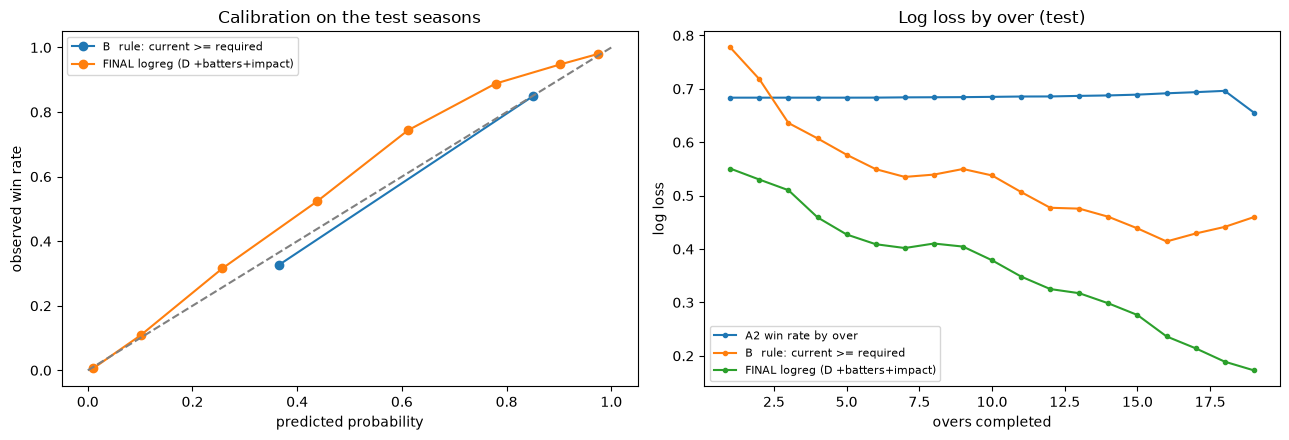

calibration slope 1.16 (1 = ideal; below 1 = overconfident), intercept 0.45 (0 = ideal)


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for k in [REF, FINAL]:
    frac, mp = calibration_curve(y_te, clip(preds[k]), n_bins=8, strategy="quantile")
    ax[0].plot(mp, frac, marker="o", label=k)
ax[0].plot([0, 1], [0, 1], ls="--", c="gray")
ax[0].set(title="Calibration on the test seasons", xlabel="predicted probability", ylabel="observed win rate")
ax[0].legend(fontsize=8)
for k in ["A2 win rate by over", REF, FINAL]:
    d = pd.DataFrame({"over": test.over, "l": row_loss(y_te, preds[k])}).groupby("over").l.mean()
    ax[1].plot(d.index, d.values, marker=".", label=k)
ax[1].set(title="Log loss by over (test)", xlabel="overs completed", ylabel="log loss"); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(out / "test_calibration_and_by_over.png", dpi=120); plt.show()

# calibration intercept and slope: regress the outcome on logit(p). Ideal = intercept 0, slope 1.
lg = np.log(clip(preds[FINAL]) / (1 - clip(preds[FINAL]))).reshape(-1, 1)
cal = LogisticRegression(C=1e6, max_iter=5000).fit(lg, y_te)
print(f"calibration slope {cal.coef_[0][0]:.2f} (1 = ideal; below 1 = overconfident), intercept {cal.intercept_[0]:.2f} (0 = ideal)")

## 7. Distribution shift check

Scoring levels have been rising. If test targets or states fall outside what the model saw in training, its predictions there are extrapolation. This section measures how much of the test data that affects.

In [8]:
tm = test.groupby("match_id").target.first(); fm = full.groupby("match_id").target.first()
print(f"train+val targets: mean {fm.mean():.0f}, max {fm.max():.0f} | test targets: mean {tm.mean():.0f}, max {tm.max():.0f}")
print(f"test matches with a target above the training maximum: {(tm > fm.max()).sum()} of {len(tm)}")

lo, hi = full[FEATURES].min(), full[FEATURES].max()
outside = ((test[FEATURES] < lo) | (test[FEATURES] > hi)).any(axis=1)
print(f"test rows with any feature outside the training range: {outside.mean():.1%}")

edges = [0, full.target.quantile(0.5), full.target.quantile(0.9), 1000]
bins = pd.cut(test.target, edges, labels=["typical (<= train median)", "high (median-90th pct)", "very high (> train 90th pct)"])
shift = (pd.DataFrame({"bin": bins, "loss_model": row_loss(y_te, preds[FINAL]), "loss_B": row_loss(y_te, preds[REF])})
         .groupby("bin", observed=True).agg(rows=("loss_model", "size"), model_log_loss=("loss_model", "mean"), ruleB_log_loss=("loss_B", "mean")).round(4))
shift

train+val targets: mean 167, max 288 | test targets: mean 195, max 287
test matches with a target above the training maximum: 0 of 138
test rows with any feature outside the training range: 1.2%


,rows,model_log_loss,ruleB_log_loss
bin,,,
typical (<= train median),584,0.3178,0.4874
high (median-90th pct),933,0.4113,0.5540
very high (> train 90th pct),917,0.3681,0.5583


## 8. Error analysis

Where does the model go wrong? Four views: by game state, the matches with the worst average loss, the most confident individual mistakes, and the win-probability curve of a few matches.

In [9]:
E = test.copy()
E["p"] = preds[FINAL]; E["loss"] = row_loss(y_te, E.p); E["lossB"] = row_loss(y_te, preds[REF])

def slice_table(col, bins=None):
    key = pd.cut(E[col], bins) if bins is not None else E[col]
    return (E.groupby(key, observed=True).agg(rows=("loss", "size"), win_rate=(LABEL, "mean"), mean_p=("p", "mean"),
                                              model_log_loss=("loss", "mean"), ruleB_log_loss=("lossB", "mean")).round(3))
print("By wickets lost"); display(slice_table("wickets_lost"))
print("By required run rate"); display(slice_table("required_run_rate", [0, 6, 8, 10, 12, 14, 18, 1000]))

By wickets lost


,rows,win_rate,mean_p,model_log_loss,ruleB_log_loss
wickets_lost,,,,,
0,431,0.724,0.587,0.461,0.586
1,500,0.704,0.634,0.347,0.517
2,430,0.616,0.619,0.395,0.540
3,379,0.538,0.476,0.421,0.550
4,256,0.520,0.485,0.344,0.516
5,198,0.328,0.307,0.327,0.509
6,110,0.273,0.223,0.248,0.503
7,63,0.143,0.139,0.305,0.621
8,40,0.050,0.066,0.110,0.533


By required run rate


,rows,win_rate,mean_p,model_log_loss,ruleB_log_loss
required_run_rate,,,,,
"(0, 6]",225,0.933,0.972,0.187,0.278
"(6, 8]",405,0.995,0.874,0.149,0.268
"(8, 10]",564,0.803,0.652,0.537,0.686
"(10, 12]",618,0.429,0.378,0.600,0.716
"(12, 14]",279,0.125,0.165,0.365,0.546
"(14, 18]",182,0.038,0.092,0.146,0.483
"(18, 1000]",161,0.000,0.013,0.013,0.454


In [10]:
meta = [c for c in ["match_id", "date", "season", "batting_team", "bowling_team", "venue_clean"] if c in E.columns]
mm = (E.groupby("match_id").agg(**{c: (c, "first") for c in meta if c != "match_id"},
                                target=("target", "first"), chase_won=(LABEL, "first"),
                                mean_p=("p", "mean"), mean_loss=("loss", "mean"), mean_lossB=("lossB", "mean"))
      .sort_values("mean_loss", ascending=False).round(3))
mm.to_csv(out / "test_match_errors.csv")
print("10 matches with the highest average log loss"); display(mm.head(10))
print(f"Matches where the model was worse than the simple rule: {(mm.mean_loss > mm.mean_lossB).sum()} of {len(mm)}")

rows_cols = [c for c in ["match_id", "season", "over", "wickets_lost", "runs_needed", "balls_left", "target"] if c in E.columns]
print("10 most confident wrong predictions (single rows)")
display(E.sort_values("loss", ascending=False)[rows_cols + [LABEL, "p", "loss"]].head(10).round(3))

10 matches with the highest average log loss


,date,season,batting_team,bowling_team,venue_clean,target,chase_won,mean_p,mean_loss,mean_lossB
match_id,,,,,,,,,,
1473468,2025-04-15,2025,Kolkata Knight Riders,Punjab Kings,Mullanpur Stadium,112,0,0.876,2.494,1.894
1473441,2025-03-24,2025,Delhi Capitals,Lucknow Super Giants,"ACA-VDCA Stadium, Visakhapatnam",210,1,0.171,2.267,0.919
1473473,2025-04-19,2025,Rajasthan Royals,Lucknow Super Giants,"Sawai Mansingh Stadium, Jaipur",181,0,0.825,1.861,1.591
1529298,2026-05-11,2026,Delhi Capitals,Punjab Kings,"HPCA Stadium, Dharamsala",211,1,0.220,1.790,0.961
1527688,2026-04-09,2026,Lucknow Super Giants,Kolkata Knight Riders,"Eden Gardens, Kolkata",182,1,0.436,1.008,0.741
1473497,2025-05-18,2025,Rajasthan Royals,Punjab Kings,"Sawai Mansingh Stadium, Jaipur",220,0,0.567,0.924,1.288
1473507,2025-05-27,2025,Royal Challengers Bengaluru,Lucknow Super Giants,"Ekana Stadium, Lucknow",228,1,0.459,0.908,0.585
1473479,2025-04-24,2025,Rajasthan Royals,Royal Challengers Bengaluru,"M Chinnaswamy Stadium, Bengaluru",206,0,0.557,0.903,1.364
1473466,2025-04-13,2025,Delhi Capitals,Mumbai Indians,"Arun Jaitley Stadium, Delhi",206,0,0.541,0.898,1.574


Matches where the model was worse than the simple rule: 30 of 138
10 most confident wrong predictions (single rows)


,match_id,season,over,wickets_lost,balls_left,target,chasing_team_won,p,loss
532,1473468,2025,8,3,72,112,0,0.979,3.875
533,1473468,2025,9,3,66,112,0,0.976,3.743
531,1473468,2025,7,2,78,112,0,0.975,3.670
530,1473468,2025,6,2,84,112,0,0.974,3.637
55,1473441,2025,2,3,108,210,1,0.032,3.445
56,1473441,2025,3,3,102,210,1,0.039,3.256
66,1473441,2025,13,6,42,210,1,0.041,3.188
61,1473441,2025,8,5,72,210,1,0.047,3.067
60,1473441,2025,7,5,78,210,1,0.047,3.047
593,1473473,2025,17,2,18,181,0,0.948,2.956


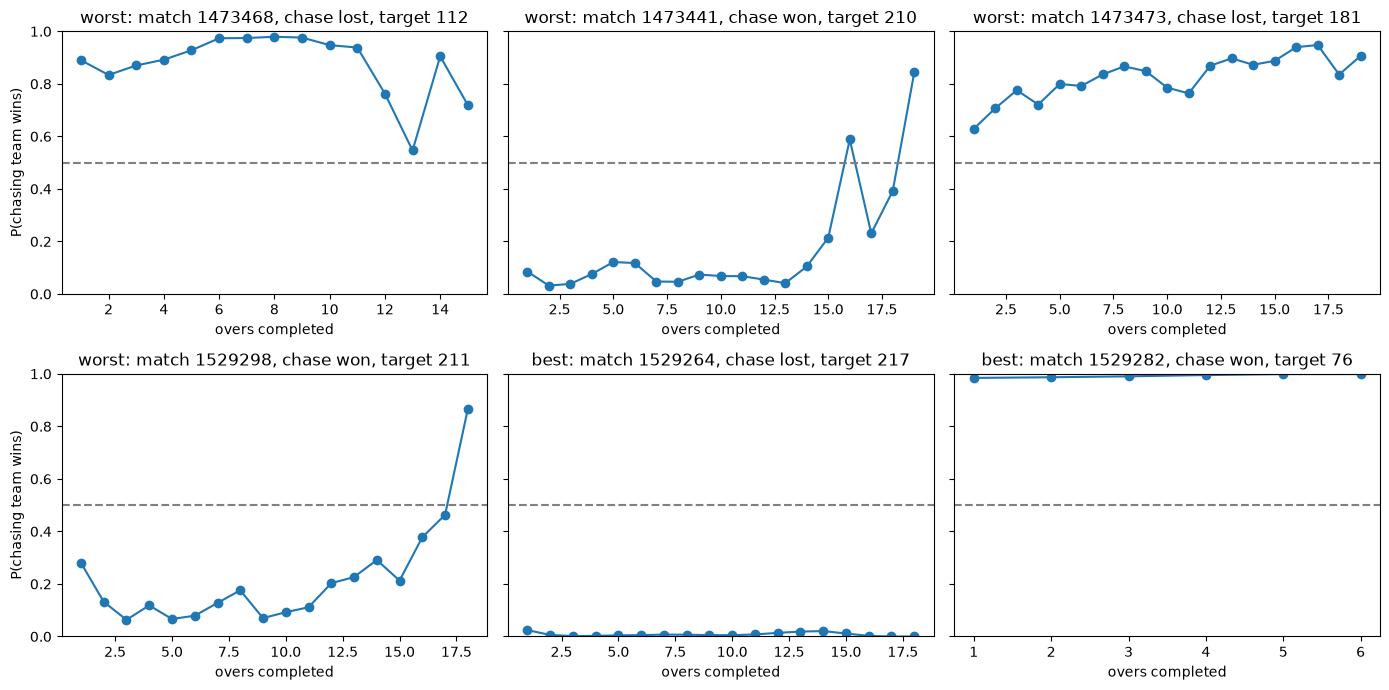

In [11]:
worst = mm.index[:4].tolist(); best = mm.index[-2:].tolist()
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for ax, mid in zip(axes.ravel(), worst + best):
    g = E[E.match_id == mid].sort_values("over")
    ax.plot(g.over, g.p, marker="o"); ax.axhline(0.5, ls="--", c="gray")
    won = int(g[LABEL].iloc[0]); tag = "worst" if mid in worst else "best"
    ax.set(title=f"{tag}: match {mid}, chase {'won' if won else 'lost'}, target {int(g.target.iloc[0])}", xlabel="overs completed", ylim=(0, 1))
axes[0, 0].set_ylabel("P(chasing team wins)"); axes[1, 0].set_ylabel("P(chasing team wins)")
fig.tight_layout(); fig.savefig(out / "test_match_trajectories.png", dpi=120); plt.show()

## 9. What the final model relies on (explanation only)

Permutation importance: how much the test log loss rises when one feature is shuffled. This **describes** the fitted model; it is not used to change it. Correlated features share credit, so a low value does not prove a feature is useless.

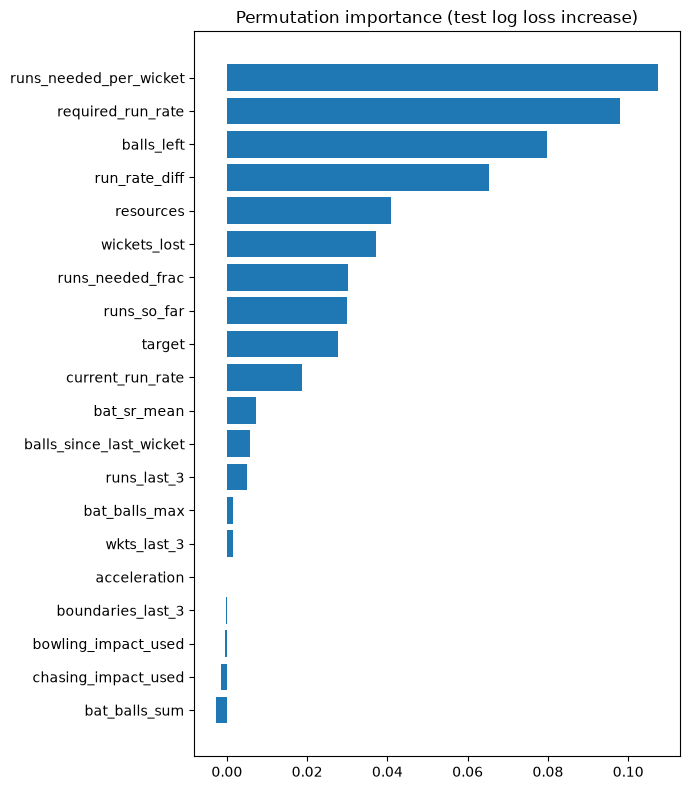

,standardised coefficient
runs_needed_per_wicket,-1.010
required_run_rate,-0.883
run_rate_diff,-0.703
runs_needed_frac,-0.670
wickets_lost,-0.446
target,-0.288
current_run_rate,-0.248
balls_since_last_wicket,-0.212
runs_last_3,-0.098
wkts_last_3,-0.066


In [12]:
rng = np.random.default_rng(RANDOM_STATE)
base = row_loss(y_te, final.predict_proba(test[FEATURES])[:, 1]).mean()
imp = {}
for f in FEATURES:
    inc = []
    for _ in range(5):
        Xp = test[FEATURES].copy(); Xp[f] = rng.permutation(Xp[f].to_numpy())
        inc.append(row_loss(y_te, final.predict_proba(Xp)[:, 1]).mean() - base)
    imp[f] = np.mean(inc)
imp = pd.Series(imp).sort_values(ascending=False)
imp.round(4).to_frame("log loss increase").to_csv(out / "test_permutation_importance.csv")
fig, ax = plt.subplots(figsize=(7, 0.35 * len(imp) + 1))
ax.barh(imp.index[::-1], imp.values[::-1]); ax.set(title="Permutation importance (test log loss increase)")
fig.tight_layout(); fig.savefig(out / "test_permutation_importance.png", dpi=120); plt.show()
if MODEL == "logreg":
    display(pd.Series(final.named_steps["clf"].coef_[0], index=FEATURES).sort_values().round(3).to_frame("standardised coefficient"))

## 10. Save the results and lock

In [13]:
res = {
    "model": MODEL, "feature_set": sel["feature_set"], "features": FEATURES, "params": PARAMS,
    "fitted_on_seasons": [int(full.season.min()), int(full.season.max())],
    "test_seasons": [int(x) for x in sorted(test.season.unique())],
    "test_matches": int(test.match_id.nunique()), "test_rows": int(len(test)),
    "test_metrics": {k: {m: float(v) for m, v in summarize(y_te, p).items()} for k, p in preds.items()},
    "calibration_slope": float(cal.coef_[0][0]), "calibration_intercept": float(cal.intercept_[0]),
}
LOCK.write_text(json.dumps(res, indent=2))
pd.concat([test[[c for c in ["match_id", "season", "over"] if c in test.columns]].reset_index(drop=True),
           pd.Series(y_te, name=LABEL), pd.DataFrame(preds)], axis=1).to_csv(out / "test_predictions.csv", index=False)
print("saved to", out.resolve())

saved to C:\Users\LEGION\OneDrive\Documents\GitHub\es335-2026\results\final


## 11. What to write down

- **The headline:** final model vs baseline B on the test seasons, with the match-bootstrap intervals. If the interval for "diff vs B" includes 0, say so.
- **Validation vs test:** compare the test log loss with the validation log loss from notebook 03. A gap is expected (2025-26 are further from the training data); explain it with the shift check in section 7.
- **Calibration:** the slope and the plot. Below 1 means overconfident.
- **Errors:** the worst matches and confident mistakes. Typically upsets (a collapse or a late blitz) that no state-only feature could foresee. Name which kind you see.
- **Limitations:** about a hundred test matches is a small sample; the model sees no information about who is bowling, pitch or dew; probabilities from one team's perspective; DLS and no-result matches were excluded.
- **Honesty line:** the test set was evaluated once, after the model was frozen in notebook 03.